# 2 · The three medical datasets

All three come from MedMNIST v2 (Yang et al., *Scientific Data* 2023) in the MedMNIST+ 224 × 224 release,
with official train / val / test splits. None of them is among the paper's 24 tasks.

| task | images | classes | source |
| --- | --- | --- | --- |
| DermaMNIST | dermoscopy photos of skin lesions | 7 | HAM10000 |
| BloodMNIST | microscopy of blood cells | 8 | Acevedo et al. 2020 |
| PneumoniaMNIST | paediatric chest X-rays | 2 | Kermany et al. 2018 |

The archives (`<task>_224.npz`) are downloaded once from https://zenodo.org/records/10519652 into `data/`.
`train.py` unpacks each split into plain `.npy` files that are memory-mapped, so data-loader workers share
one copy in RAM instead of each holding a gigabyte.

In [1]:
import sys, json, time, math
from pathlib import Path
ROOT = Path.cwd().parent            # demo/vpt
sys.path.insert(0, str(ROOT))
import numpy as np, torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

torch 2.11.0+cu128 | CUDA: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [2]:
from medmnist import INFO
TASKS = ["dermamnist", "bloodmnist", "pneumoniamnist"]
DATA = ROOT / "data"

def unpack(task, split):
    """Same as train.medmnist_npy: one-time conversion of a split to .npy, then memory-mapped access."""
    out = DATA / f"{task}_224"; out.mkdir(exist_ok=True)
    xi, yi = out / f"{split}_images.npy", out / f"{split}_labels.npy"
    if not xi.exists():
        with np.load(DATA / f"{task}_224.npz") as z:
            np.save(xi, z[f"{split}_images"]); np.save(yi, z[f"{split}_labels"][:, 0])
    return np.load(xi, mmap_mode="r"), np.load(yi)

data = {t: {s: unpack(t, s) for s in ("train", "val", "test")} for t in TASKS}
for t in TASKS:
    sizes = {s: len(data[t][s][1]) for s in ("train", "val", "test")}
    print(f"{t:15s} {sizes}  image array {data[t]['test'][0].shape[1:]}  classes {len(INFO[t]['label'])}")

dermamnist      {'train': 7007, 'val': 1003, 'test': 2005}  image array (224, 224, 3)  classes 7
bloodmnist      {'train': 11959, 'val': 1712, 'test': 3421}  image array (224, 224, 3)  classes 8
pneumoniamnist  {'train': 4708, 'val': 524, 'test': 624}  image array (224, 224)  classes 2


## Class balance

DermaMNIST is strongly imbalanced: two thirds of the images are melanocytic nevi. A model that always
answers "nevus" scores about 67% accuracy but only 1/7 = 14% balanced accuracy (the mean of the per-class
recalls). That is why the talk reports balanced accuracy and selects models on it.

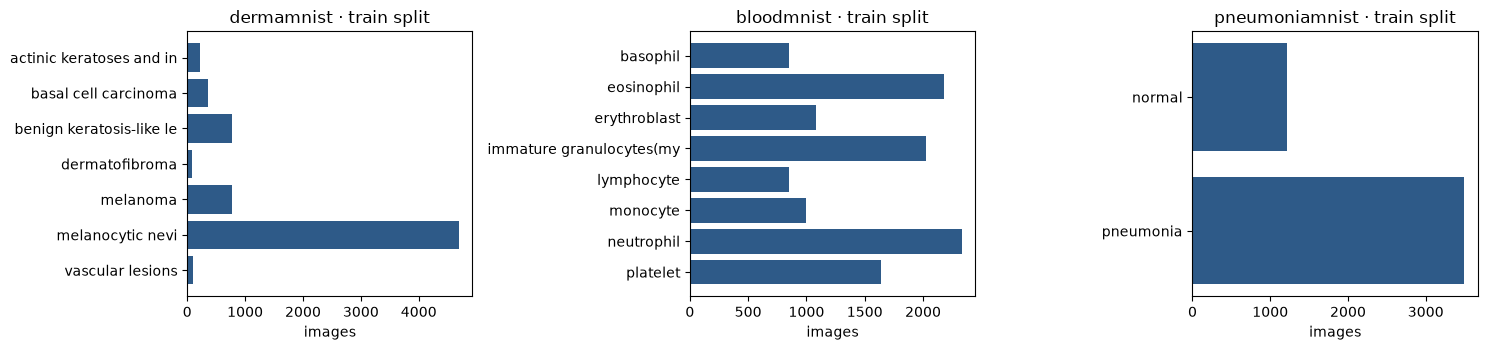

dermamnist      always predicting the majority class: accuracy 66.9%, balanced accuracy 14.3%
bloodmnist      always predicting the majority class: accuracy 19.5%, balanced accuracy 12.5%
pneumoniamnist  always predicting the majority class: accuracy 62.5%, balanced accuracy 50.0%


In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, t in zip(axes, TASKS):
    y = data[t]["train"][1]
    names = [INFO[t]["label"][str(i)][:24] for i in range(len(INFO[t]["label"]))]
    counts = np.bincount(y, minlength=len(names))
    ax.barh(names, counts, color="#2E5A88"); ax.invert_yaxis()
    ax.set_title(f"{t} · train split"); ax.set_xlabel("images")
plt.tight_layout(); plt.show()
for t in TASKS:
    y = data[t]["test"][1]
    majority = np.bincount(y).argmax()
    print(f"{t:15s} always predicting the majority class: accuracy {100 * (y == majority).mean():.1f}%, balanced accuracy {100 / len(np.unique(y)):.1f}%")

## What the images look like

One random test image per class (fixed seed), the same way the live demo's thumbnails were drawn by
`export_samples.py`.

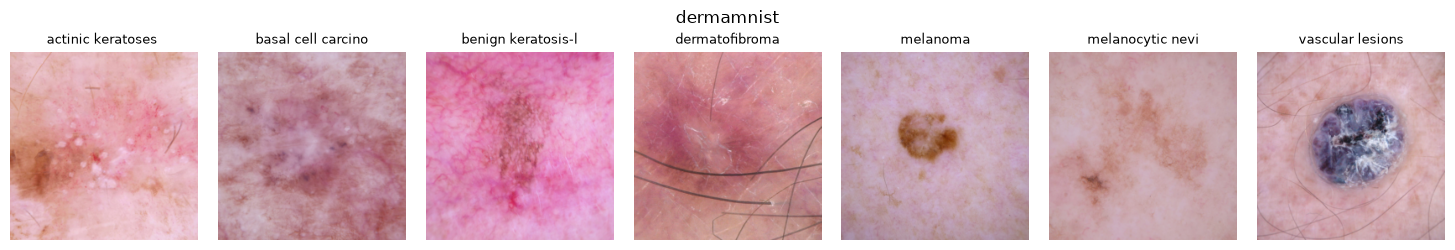

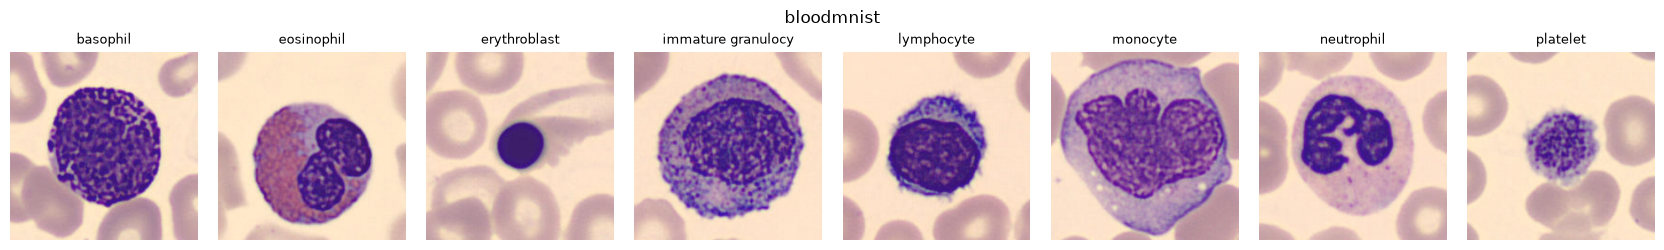

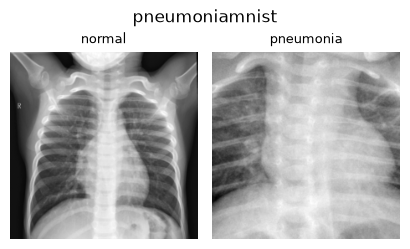

In [4]:
rng = np.random.default_rng(0)
for t in TASKS:
    x, y = data[t]["test"]
    n = len(INFO[t]["label"])
    fig, axes = plt.subplots(1, n, figsize=(2.1 * n, 2.5))
    for c, ax in enumerate(np.atleast_1d(axes)):
        i = rng.choice(np.flatnonzero(y == c))
        ax.imshow(np.asarray(x[i]), cmap="gray"); ax.axis("off")
        ax.set_title(INFO[t]["label"][str(c)][:18], fontsize=9)
    fig.suptitle(t); plt.tight_layout(); plt.show()

## The 1,000-image subsets

The paper's main benchmark, VTAB-1k, gives every task exactly 1,000 training images. Our low-data runs do
the same: 1,000 images drawn at random (seed 0) from the train split; val and test stay complete.

In [5]:
for t in TASKS:
    y = data[t]["train"][1]
    idx = np.random.default_rng(0).choice(len(y), size=1000, replace=False)     # exactly what train.py --subset 1000 does
    print(f"{t:15s} classes in the 1k subset: {np.bincount(y[idx], minlength=len(INFO[t]['label'])).tolist()}")

dermamnist      classes in the 1k subset: [29, 59, 118, 11, 117, 652, 14]
bloodmnist      classes in the 1k subset: [74, 198, 98, 172, 57, 79, 188, 134]
pneumoniamnist  classes in the 1k subset: [265, 735]
